### JS08 Lab Assignment

1. Construct a clustering model using Agglomerative Clustering with all usable variables.
2. Create a scatterplot based on the dataset using two variables, namely `Avg_Credit_Limit` and `Total_Credit_Cards`. Depict the cluster configuration based on these two features.
3. Determine the value of the silhouette score and the DBI of the model.

#### Question 1 - Agglomerative Clustering model

The identifier columns (`Sl_No` and `Customer Key`) are excluded. The five remaining numeric columns are the usable clustering variables. Standardization prevents variables with larger numeric scales from dominating distance calculations.

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("CC_Customer_Dataset (2).csv")
feature_columns = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made",
]
X = df[feature_columns].copy()
X_scaled = StandardScaler().fit_transform(X)

candidate_scores = {}
for k in range(2, 9):
    candidate_labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_scaled)
    candidate_scores[k] = silhouette_score(X_scaled, candidate_labels)

optimal_k = max(candidate_scores, key=candidate_scores.get)
model = AgglomerativeClustering(n_clusters=optimal_k, linkage="ward")
df["Cluster"] = model.fit_predict(X_scaled)

print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1] - 1} original columns")
print(f"Usable clustering variables: {feature_columns}")
print("Silhouette scores by k:")
for k, score in candidate_scores.items():
    print(f"  k={k}: {score:.4f}")
print(f"Selected number of clusters: {optimal_k}")
print("Cluster sizes:")
print(df["Cluster"].value_counts().sort_index())

C:\Users\icha\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Dataset shape: 660 rows x 7 original columns
Usable clustering variables: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
Silhouette scores by k:
  k=2: 0.4177
  k=3: 0.5148
  k=4: 0.3481
  k=5: 0.2569
  k=6: 0.2268
  k=7: 0.2163
  k=8: 0.2187
Selected number of clusters: 3
Cluster sizes:
Cluster
0    385
1    225
2     50
Name: count, dtype: int64


#### Question 2 - Cluster scatterplot

The labels shown below were generated from all five usable variables; the plot displays the requested two variables.

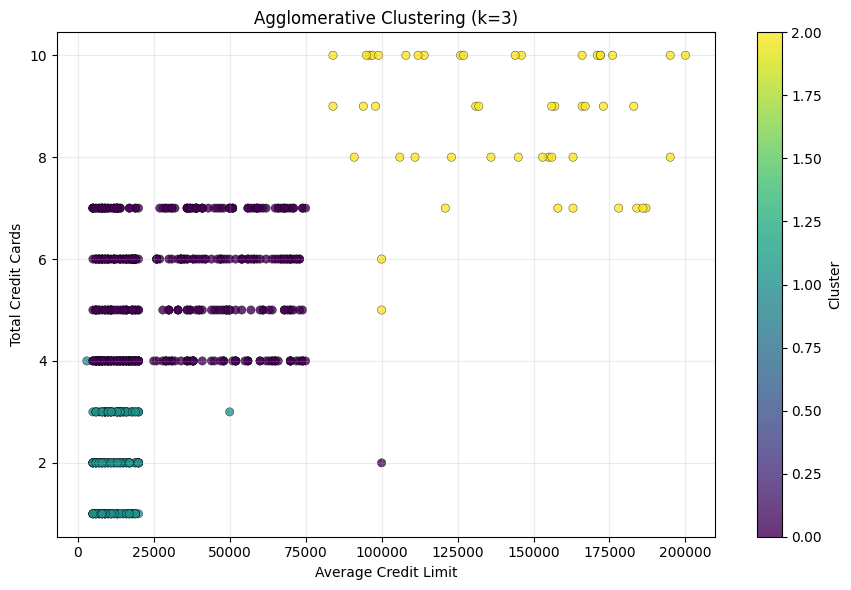

In [4]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df["Avg_Credit_Limit"],
    df["Total_Credit_Cards"],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.8,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.title(f"Agglomerative Clustering (k={optimal_k})")
plt.colorbar(scatter, label="Cluster")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### Question 3 - Silhouette score and Davies-Bouldin Index (DBI)

In [5]:
from sklearn.metrics import davies_bouldin_score

silhouette = silhouette_score(X_scaled, df["Cluster"])
dbi = davies_bouldin_score(X_scaled, df["Cluster"])

print(f"Silhouette score: {silhouette:.4f}")
print(f"Davies-Bouldin Index (DBI): {dbi:.4f}")
print("A higher silhouette score is better, while a lower DBI is better.")

Silhouette score: 0.5148
Davies-Bouldin Index (DBI): 0.6810
A higher silhouette score is better, while a lower DBI is better.
